# Pipeline Segmentado de Auditoría, Limpieza y Construcción de `dataset_trabajo`

Este notebook implementa de forma modular y trazable todos los criterios de validación, reparación y filtrado sobre **todas las hojas** de los tres archivos Excel (`Totalizadores Planta 2020_2022.xlsx`, `Totalizadores Planta - 2021_2023.xlsx`, `Totalizadores Planta 2022_2023.xlsx`) para construir el archivo final `data/processed/dataset_trabajo.csv`.

### Estructura Segmentada del Pipeline
1. **Etapa 0 — Configuración e Integridad:** Verificación SHA-256 de los archivos crudos y definición de prioridades temporales (`2022_2023 > 2021_2023 > 2020_2022`).
2. **Etapa 1 — Auditoría de Días con $>25$ Registros (50, 75 o 100 filas) en `Consolidado EE`:** Verificación bloque contra bloque para determinar si las repeticiones de 25 horas son copias idénticas, plantillas vacías/ceros o registros de días distintos.
3. **Etapa 2 — Limpieza Horaria, Reparación de Typos y Desempate entre Archivos:**
   - Borrado de registros extra a las `23:59:59`.
   - Reparación del día con fecha incrustada `1900-01-01` junto a las horas.
   - Corrección posicional de *typos* horarios (incluyendo rebotes como `16hs -> 15hs -> 16hs`, duplicados `15hs -> 15hs` e inversiones `09hs -> 08hs`).
   - Unión horizontal de **todas las hojas** (conservando **una única columna `DIA` y una única columna `HORA`**) y desempate entre archivos quedándose siempre con el **archivo más nuevo**.
   - Verificacion de reinicio del contador del dia.
4. **Etapa 3 — Condición Acumulativa en `Consolidado EE` y Verificación del Cierre (`23:59`) mediante MAD:**
   - Cálculo robusto de la Mediana y la Desviación Absoluta Mediana (**MAD**) sobre los valores de cierre a las `23:59`.
   - Reporte detallado de cualquier caída o anomalía acumulativa en las variables de `Consolidado EE` y validación de su cierre a las `23:59` con el método MAD.
5. **Etapa 4 — Evaluación de Casos Especiales en `Frio (Kw)` (`Consolidado EE`) mediante MAD:**
   - Días que **no arrancan a las `00:00`** (arrancan a otra hora).
   - Días con `0` a las `00:00`, un **dato GIGANTE a la `01:00`** y retorno a `0` (o valor normal) a las `02:00`.
6. **Etapa 5 — Filtrado de Días Inválidos y Tabla Completa de Días Borrados:**
   - Eliminación de días con menor cantidad de horas (sin registro a las `23:59` o incompletos) y días que violan la condición acumulativa o fallan la validación MAD a las `23:59`.
   - Generación de la **tabla completa de días borrados** identificando `DIA`, `Archivo_Origen`, `Etapa_Filtro` y `Motivo_Detallado`.
7. **Etapa 6 — Visualización Diagnóstica del Método MAD y Días Eliminados.**
8. **Etapa 7 — Exportación de `data/processed/dataset_trabajo.csv` y Actualización de `checksums.json`.**

In [51]:
import sys
import hashlib
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Agregar la raíz del proyecto al path para importar desde src/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

try:
    from src.auxiliar_functions import (
        RAW_DATA_DIR,
        DATA_DIR,
        SEMILLA,
        huella,
        verificar_checksums,
    )
    verificar_checksums()
except Exception as e:
    print(f"Aviso al importar src.auxiliar_functions: {e}")
    DATA_DIR = PROJECT_ROOT / "data"
    RAW_DATA_DIR = DATA_DIR / "raw" if (DATA_DIR / "raw").exists() else DATA_DIR
    SEMILLA = 42

# Archivos ordenados estrictamente del MÁS NUEVO al MÁS VIEJO
ruta_2022_2023 = RAW_DATA_DIR / "Totalizadores Planta 2022_2023.xlsx"
ruta_2021_2023 = RAW_DATA_DIR / "Totalizadores Planta - 2021_2023.xlsx"
ruta_2020_2022 = RAW_DATA_DIR / "Totalizadores Planta 2020_2022.xlsx"

ARCHIVOS_EXCEL = [
    ("2022_2023", ruta_2022_2023),
    ("2021_2023", ruta_2021_2023),
    ("2020_2022", ruta_2020_2022),
]

HORAS_CANONICAS = [f"{h:02d}:00" for h in range(24)] + ["23:59"]
COL_TARGET = "Frio (Kw)_Consolidado EE"
TOL = 1e-3          # Tolerancia numérica para diferencias de coma flotante
UMBRAL_MAD = 3.5    # Umbral de Z-score robusto basado en MAD para validar el cierre 23:59

Verificación de integridad completada: 3 archivo(s) coinciden.


--- 
## Etapa 1: Verificación de Días con $>25$ Registros (50, 75 o 100 filas) en `Consolidado EE`

Algunos días de fin de mes (ej. meses de 28 o 30 días) presentan **50, 75 o 100 registros** (25 horas del `00:00` al `23:59` repetidas 2, 3 o 4 veces bajo la misma fecha).

En esta celda tomamos la hoja **`Consolidado EE`** de cada archivo Excel y comparamos cada bloque adicional (`Bloque 1, 2, 3`) contra el primer bloque del día (`Bloque 0`), distinguiendo de forma exacta:
1. **Copia idéntica del Bloque 0:** Los valores numéricos y posiciones `NaN` coinciden exactamente.
2. **Bloque fantasma en Cero / `NaN`:** El bloque repetido tiene todos sus valores en `0` o `NaN` (relleno de plantilla para completar 31 días).
3. **Datos distintos (posible día distinto o residuo de plantilla):** Los valores de `Consolidado EE` cambian respecto al `Bloque 0`.

In [52]:
def normalizar_hora_base(serie_hora):
    """Quita prefijos de fecha (1899-12-30, 1900-01-01), decimales .0 y asegura dos dígitos en la hora."""
    s = serie_hora.astype(str).str.strip()
    s = s.str.replace(r"^\d{4}-\d{2}-\d{2}\s+", "", regex=True)
    s = s.str.replace(r"\.0$", "", regex=True)
    s = s.str.replace(r"^(\d):", r"0\1:", regex=True)
    return s

def auditar_dias_repetidos_consolidado_ee(archivos_excel):
    """
    Evalúa en la hoja 'Consolidado EE' todos los días que tienen más de 25 registros
    (una vez descontado el registro extra 23:59:59) para verificar si los bloques
    adicionales son copias exactas o contienen datos distintos.
    """
    registros = []

    for etiqueta, ruta in archivos_excel:
        xls = pd.ExcelFile(ruta)
        mapa_hojas = {h.strip(): h for h in xls.sheet_names}
        if "Consolidado EE" not in mapa_hojas:
            continue

        df = pd.read_excel(xls, sheet_name=mapa_hojas["Consolidado EE"])
        df.columns = df.columns.astype(str).str.strip()
        df = df.loc[:, ~df.columns.str.contains("^Unnamed", case=False)]
        df = df.dropna(subset=["DIA", "HORA"]).copy()
        df["DIA"] = pd.to_datetime(df["DIA"], errors="coerce").dt.normalize()
        df = df.dropna(subset=["DIA"]).copy()

        s_hora = normalizar_hora_base(df["HORA"])
        # Excluir 23:59:59 antes de contar filas por día para no confundir 26 filas con bloques repetidos
        mask_235959 = s_hora.str.startswith("23:59:59")
        df = df[~mask_235959].copy()
        s_hora = s_hora[~mask_235959]
        df["HORA_CLEAN"] = s_hora.str.replace(r"^(\d{2}:\d{2}):\d{2}$", r"\1", regex=True)

        cols_num = [c for c in df.columns if c not in ("DIA", "HORA", "HORA_CLEAN")]
        for c in cols_num:
            df[c] = pd.to_numeric(df[c], errors="coerce")

        # Identificar cada reinicio a 00:00 dentro de un mismo DIA como un bloque distinto
        es_nuevo_bloque = (df["HORA_CLEAN"] == "00:00") & (df["DIA"] == df["DIA"].shift(1))
        df["ID_BLOQUE"] = es_nuevo_bloque.groupby(df["DIA"]).cumsum()

        conteo_dia = df.groupby("DIA").size()
        dias_mas_25 = conteo_dia[conteo_dia > 25].index

        for d in dias_mas_25:
            sub = df[df["DIA"] == d]
            n_filas_dia = len(sub)
            n_bloques = sub["ID_BLOQUE"].nunique()

            b0 = (
                sub[sub["ID_BLOQUE"] == 0]
                .drop_duplicates(subset=["HORA_CLEAN"], keep="first")
                .set_index("HORA_CLEAN")[cols_num]
            )

            for b_id in sorted(sub["ID_BLOQUE"].unique()):
                if b_id == 0:
                    continue
                bx = (
                    sub[sub["ID_BLOQUE"] == b_id]
                    .drop_duplicates(subset=["HORA_CLEAN"], keep="first")
                    .set_index("HORA_CLEAN")[cols_num]
                )

                horas_comunes = b0.index.intersection(bx.index)
                b0_al = b0.loc[horas_comunes]
                bx_al = bx.loc[horas_comunes]

                arr0 = b0_al.to_numpy(dtype=float)
                arrx = bx_al.to_numpy(dtype=float)

                # ¿El bloque extra está completamente en 0 o NaN?
                es_vacio_o_cero = bool(np.all(np.isnan(arrx) | (np.abs(arrx) < 1e-6)))

                # ¿Es copia exacta? (misma máscara de NaN y valores iguales dentro de tolerancia)
                misma_mascara_nan = np.array_equal(np.isnan(arr0), np.isnan(arrx))
                iguales_num = np.allclose(arr0, arrx, atol=1e-4, rtol=1e-5, equal_nan=True)
                es_copia_exacta = bool(misma_mascara_nan and iguales_num)

                diff_abs = np.abs(np.nan_to_num(arr0, nan=0.0) - np.nan_to_num(arrx, nan=0.0))
                max_diff = float(np.max(diff_abs)) if diff_abs.size > 0 else 0.0

                frio_b0_2359 = b0_al.loc["23:59", "Frio (Kw)"] if ("23:59" in b0_al.index and "Frio (Kw)" in b0_al.columns) else np.nan
                frio_bx_2359 = bx_al.loc["23:59", "Frio (Kw)"] if ("23:59" in bx_al.index and "Frio (Kw)" in bx_al.columns) else np.nan

                if es_copia_exacta:
                    clasificacion = "1. Copia exacta del Bloque 0"
                elif es_vacio_o_cero:
                    clasificacion = "2. Bloque fantasma en Cero / NaN (relleno fin de mes)"
                else:
                    clasificacion = "3. Datos DISTINTOS (valores cambian respecto al Bloque 0)"

                registros.append({
                    "Archivo": etiqueta,
                    "DIA": d.strftime("%Y-%m-%d"),
                    "Filas_Totales_Dia": n_filas_dia,
                    "Total_Bloques": n_bloques,
                    "Bloque_Evaluado": b_id,
                    "Filas_Bloque": len(bx),
                    "Es_Copia_Identica": es_copia_exacta,
                    "Clasificacion": clasificacion,
                    "Frio_2359_Bloque0": frio_b0_2359,
                    "Frio_2359_BloqueX": frio_bx_2359,
                    "Max_Dif_Abs_EE": max_diff,
                })

    return pd.DataFrame(registros)

df_auditoria_bloques_ee = auditar_dias_repetidos_consolidado_ee(ARCHIVOS_EXCEL)

print("=== RESUMEN DE DÍAS CON >25 REGISTROS (50, 75, 100 FILAS) EN 'Consolidado EE' ===")
if not df_auditoria_bloques_ee.empty:
    resumen_bloques = (
        df_auditoria_bloques_ee.groupby(["Archivo", "Filas_Totales_Dia", "Clasificacion"], as_index=False)
        .agg(
            Dias_Afectados=("DIA", "nunique"),
            Bloques_Extra_Analizados=("Bloque_Evaluado", "count"),
            Max_Diferencia_Observada=("Max_Dif_Abs_EE", "max"),
        )
    )
    display(resumen_bloques)

    casos_distintos = df_auditoria_bloques_ee[~df_auditoria_bloques_ee["Es_Copia_Identica"]]
    print(f"\nBloques que NO son copia idéntica del Bloque 0: {len(casos_distintos)}")
    if not casos_distintos.empty:
        display(casos_distintos.head(30))
    else:
        display(df_auditoria_bloques_ee.head(20))
else:
    print("No se detectaron días con más de 25 registros en Consolidado EE.")

=== RESUMEN DE DÍAS CON >25 REGISTROS (50, 75, 100 FILAS) EN 'Consolidado EE' ===


,Archivo,Filas_Totales_Dia,Clasificacion,Dias_Afectados,Bloques_Extra_Analizados,Max_Diferencia_Observada
0,2020_2022,50,3. Datos DISTINTOS (valores cambian respecto a...,6,6,"5,540,456.00"
1,2020_2022,100,3. Datos DISTINTOS (valores cambian respecto a...,2,6,"5,635,741.64"
2,2021_2023,50,3. Datos DISTINTOS (valores cambian respecto a...,6,6,"269,128.00"
3,2021_2023,99,3. Datos DISTINTOS (valores cambian respecto a...,1,3,"14,191.91"
4,2021_2023,100,3. Datos DISTINTOS (valores cambian respecto a...,1,3,"5,635,741.64"
5,2022_2023,50,3. Datos DISTINTOS (valores cambian respecto a...,5,5,"22,004.00"
6,2022_2023,99,3. Datos DISTINTOS (valores cambian respecto a...,1,3,"14,191.91"



Bloques que NO son copia idéntica del Bloque 0: 32


,Archivo,DIA,Filas_Totales_Dia,Total_Bloques,Bloque_Evaluado,Filas_Bloque,Es_Copia_Identica,Clasificacion,Frio_2359_Bloque0,Frio_2359_BloqueX,Max_Dif_Abs_EE
0,2022_2023,2022-09-30,50,2,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,"26,011.00","20,598.00","8,961.00"
1,2022_2023,2022-11-30,50,2,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,"16,395.00","17,252.00","3,657.48"
2,2022_2023,2023-02-28,99,4,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,NaN,NaN,"10,607.00"
3,2022_2023,2023-02-28,99,4,2,25,False,3. Datos DISTINTOS (valores cambian respecto a...,NaN,NaN,"11,352.41"
4,2022_2023,2023-02-28,99,4,3,25,False,3. Datos DISTINTOS (valores cambian respecto a...,NaN,NaN,"14,191.91"
5,2022_2023,2023-04-30,50,2,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,"21,227.00","22,816.00","4,534.83"
6,2022_2023,2023-06-30,50,2,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,"25,359.00","20,267.00","22,004.00"
7,2022_2023,2023-09-30,50,2,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,"18,097.00","13,444.00","10,072.00"
8,2021_2023,2021-09-30,50,2,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,"21,007.00","22,364.00","2,442.00"
9,2021_2023,2021-11-30,50,2,1,25,False,3. Datos DISTINTOS (valores cambian respecto a...,"15,860.00","11,561.00","12,913.00"


--- 
## Etapa 2: Limpieza Horaria (`1900-01-01`, `23:59:59`, Typos `16->15->16`) y Unificación Priorizando el Archivo Más Nuevo

En este segmento procesamos **todas las hojas de los 3 archivos Excel** aplicando en orden:
1. **Reparación de fecha incrustada en `HORA` (`1900-01-01`):** Detectamos las filas donde `HORA` contiene una fecha (como `1900-01-01 HH:MM:SS` en el día `2021-07-21`), registramos el hallazgo y extraemos únicamente la hora.
2. **Borrado de registros `23:59:59`:** Eliminamos todas las filas con hora `23:59:59` y las registramos en el log de filas eliminadas.
3. **Eliminación de bloques repetidos (`>25` filas):** Conservamos únicamente el `Bloque 0` (primer bloque de 25 horas del día) y descartamos las repeticiones.
4. **Corrección de *typos* horarios (`reparar_secuencia_horaria`):**
   - **Paso A (Sándwich de 3 horas):** Si $h_{i-1}$ y $h_{i+1}$ están separadas por exactamente 2 horas canónicas (ej. `13:00 -> 16:00 -> 15:00 -> 16:00`, donde el primer `16:00` está entre `13:00` y `15:00`; o `14:00 -> 15:00 -> 15:00 -> 17:00`; o `10:00 -> 23:00 -> 12:00`), corrige la hora central a su valor canónico (`14:00`, `16:00`, `11:00`).
   - **Paso B (Ancla de 4 horas para inversiones o rebotes):** Si $h_{i-1}$ y $h_{i+2}$ distan 3 horas canónicas (ej. `07:00 -> 09:00 -> 08:00 -> 10:00` o `15:00 -> 16:00 -> 15:00 -> 18:00`), repara el par intermedio.
   - **Paso C (Alineación canónica en días completos de 25 filas):** Si el día tiene 25 registros, inicia en `00:00`, cierra en `23:59` y al menos 22/25 posiciones coinciden con la grilla canónica, corrige cualquier desvío puntual remanente.
5. **Unificación de todas las hojas y desempate entre archivos:**
   - Dentro de cada archivo, unimos todas sus hojas usando `["DIA", "HORA"]` como clave única (garantizando **una sola columna `DIA` y una sola columna `HORA`**).
   - Entre archivos distintos, para cualquier `DIA` que aparezca en más de un Excel, **nos quedamos siempre con el día completo del archivo más nuevo** (`2022_2023 > 2021_2023 > 2020_2022`).

In [53]:
log_reparaciones_horarias = []
log_filas_extra_borradas = []
log_solapamiento_archivos = []

HORAS_REGULARES = HORAS_CANONICAS[:-1]  # '00:00' a '23:00'

def reparar_secuencia_horaria(h_list):
    """
    Corrige typos en la secuencia horaria de un día (ej. 16->15->16, 15->15->17, 09->08).
    Devuelve una nueva lista de horas corregidas.
    """
    h = list(h_list)
    n = len(h)
    if n < 3:
        return h

    # Paso A: Sándwich de 3 elementos (h[i-1], h[i], h[i+1])
    # Ejemplo: 13:00, 16:00, 15:00, 16:00 -> en i=1, prev=13:00 y next=15:00 (dif=2) -> corrige 16:00 a 14:00
    for i in range(1, n - 1):
        prev_h, curr_h, next_h = h[i - 1], h[i], h[i + 1]
        if prev_h in HORAS_REGULARES and next_h in HORAS_REGULARES:
            idx_p = HORAS_REGULARES.index(prev_h)
            idx_n = HORAS_REGULARES.index(next_h)
            if idx_n - idx_p == 2:
                esperada = HORAS_REGULARES[idx_p + 1]
                if curr_h != esperada:
                    h[i] = esperada

    # Paso B: Ancla de 4 elementos (h[i-1], h[i], h[i+1], h[i+2])
    # Cubre inversiones (07:00, 09:00, 08:00, 10:00) y rebotes (15:00, 16:00, 15:00, 18:00)
    for i in range(1, n - 2):
        h_prev, h_a, h_b, h_post = h[i - 1], h[i], h[i + 1], h[i + 2]
        if h_prev in HORAS_REGULARES and h_post in HORAS_REGULARES:
            idx_prev = HORAS_REGULARES.index(h_prev)
            idx_post = HORAS_REGULARES.index(h_post)
            if idx_post - idx_prev == 3:
                esp_a = HORAS_REGULARES[idx_prev + 1]
                esp_b = HORAS_REGULARES[idx_prev + 2]
                if h_a != esp_a or h_b != esp_b:
                    h[i] = esp_a
                    h[i + 1] = esp_b

    # Paso C: Si el día tiene 25 filas, arranca en 00:00, cierra en 23:59 y >=22 coinciden con HORAS_CANONICAS
    if n == 25 and h[0] == "00:00" and h[-1] == "23:59":
        coincidencias = sum(1 for a, b in zip(h, HORAS_CANONICAS) if a == b)
        if coincidencias >= 22 and h != HORAS_CANONICAS:
            h = HORAS_CANONICAS.copy()

    return h


def limpiar_y_auditar_hoja(df_raw, archivo, hoja):
    df = df_raw.copy()
    df.columns = df.columns.astype(str).str.strip()
    df = df.loc[:, ~df.columns.str.contains("^Unnamed", case=False)]
    df = df.loc[:, ~df.columns.duplicated()]

    # Normalizar nombres de columnas clave si vinieran con distinta capitalización
    mapa_claves = {}
    for c in df.columns:
        if c.upper() == "DIA":
            mapa_claves[c] = "DIA"
        elif c.upper() == "HORA":
            mapa_claves[c] = "HORA"
    df = df.rename(columns=mapa_claves)

    if "DIA" not in df.columns or "HORA" not in df.columns:
        return pd.DataFrame()

    df = df.dropna(subset=["DIA", "HORA"]).copy()
    df["DIA"] = pd.to_datetime(df["DIA"], errors="coerce").dt.normalize()
    df = df.dropna(subset=["DIA"]).copy()

    s_hora_raw = df["HORA"].astype(str).str.strip()

    # 1. Detectar y reparar fecha incrustada en HORA (ej. 1900-01-01 HH:MM:SS)
    mask_fecha_en_hora = s_hora_raw.str.match(r"^\d{4}-\d{2}-\d{2}\s+") & ~s_hora_raw.str.startswith("1899-12-30")
    if mask_fecha_en_hora.any():
        for d in df.loc[mask_fecha_en_hora, "DIA"].unique():
            sub_h = s_hora_raw[mask_fecha_en_hora & (df["DIA"] == d)]
            log_reparaciones_horarias.append({
                "DIA": d.strftime("%Y-%m-%d"),
                "Archivo": archivo,
                "Hoja": hoja,
                "Tipo_Reparacion": "1. Fecha incrustada en HORA (1900-01-01)",
                "Filas_Reparadas": int(len(sub_h)),
                "Detalle": f"Se limpió prefijo de fecha conservando la hora. Ejemplos: {sub_h.unique().tolist()[:2]}"
            })

    s_hora = normalizar_hora_base(s_hora_raw)

    # 2. Detectar y BORRAR registros a las 23:59:59
    mask_235959 = s_hora.str.startswith("23:59:59")
    if mask_235959.any():
        for d in df.loc[mask_235959, "DIA"].unique():
            n_borradas = int((mask_235959 & (df["DIA"] == d)).sum())
            log_filas_extra_borradas.append({
                "DIA": d.strftime("%Y-%m-%d"),
                "Archivo": archivo,
                "Hoja": hoja,
                "Motivo": "Registro extra 23:59:59",
                "Filas_Borradas": n_borradas,
            })
        df = df[~mask_235959].copy()
        s_hora = s_hora[~mask_235959]

    # Truncar segundos (:00 o :01) al formato canónico HH:MM
    df["HORA"] = s_hora.str.replace(r"^(\d{2}:\d{2}):\d{2}$", r"\1", regex=True)

# 3. Detectar bloques repetidos (>25 registros) y REASIGNARLOS a días consecutivos
    es_nuevo_bloque = (df["HORA"] == "00:00") & (df["DIA"] == df["DIA"].shift(1))
    id_bloque = es_nuevo_bloque.groupby(df["DIA"]).cumsum()
    mask_bloques_extra = id_bloque > 0
    
    if mask_bloques_extra.any():
        for d, grp in df[mask_bloques_extra].groupby("DIA"):
            log_filas_extra_borradas.append({
                "DIA": d.strftime("%Y-%m-%d"),
                "Archivo": archivo,
                "Hoja": hoja,
                "Motivo": "Bloques extra conservados (reasignados a días consecutivos)",
                "Filas_Borradas": 0, # Queda en 0 porque los estamos conservando
            })
        
        # Desplazamos las fechas sumando el id_bloque en días
        df["DIA"] = df["DIA"] + pd.to_timedelta(id_bloque, unit="D")

    # 4. Detectar y corregir typos en la secuencia horaria
    horas_corregidas = []
    for d, grupo in df.groupby("DIA", sort=False):
        h_orig = grupo["HORA"].tolist()
        h_nueva = reparar_secuencia_horaria(h_orig)
        if h_nueva != h_orig:
            cambios = [
                f"pos {idx} ({o} -> {n})"
                for idx, (o, n) in enumerate(zip(h_orig, h_nueva))
                if o != n
            ]
            log_reparaciones_horarias.append({
                "DIA": d.strftime("%Y-%m-%d"),
                "Archivo": archivo,
                "Hoja": hoja,
                "Tipo_Reparacion": "2. Typo en secuencia horaria",
                "Filas_Reparadas": int(len(cambios)),
                "Detalle": "; ".join(cambios),
            })
        horas_corregidas.extend(h_nueva)

    df["HORA"] = horas_corregidas
    df = df.drop_duplicates(subset=["DIA", "HORA"], keep="first")
    return df


# --- Carga y unión horizontal de TODAS las hojas por archivo ---
dfs_por_archivo = []
dias_ya_asignados = set()

for etiqueta, ruta in ARCHIVOS_EXCEL:
    xls = pd.ExcelFile(ruta)
    hojas_limpias = []

    for hoja in xls.sheet_names:
        hoja_clean = hoja.strip()
        df_raw = pd.read_excel(xls, sheet_name=hoja)
        df_h = limpiar_y_auditar_hoja(df_raw, etiqueta, hoja_clean)

        if not df_h.empty:
            renombres = {
                c: f"{c}_{hoja_clean}"
                for c in df_h.columns
                if c not in ("DIA", "HORA")
            }
            df_h = df_h.rename(columns=renombres).set_index(["DIA", "HORA"])
            hojas_limpias.append(df_h)

    df_arch = pd.concat(hojas_limpias, axis=1, join="outer").reset_index()
    df_arch["_archivo_origen"] = etiqueta

    # Regla de prioridad: quedarnos SIEMPRE con el archivo más nuevo para cada DIA completo
    dias_en_archivo = set(df_arch["DIA"].unique())
    dias_solapados = sorted(dias_en_archivo.intersection(dias_ya_asignados))
    for d_sol in dias_solapados:
        log_solapamiento_archivos.append({
            "DIA": d_sol.strftime("%Y-%m-%d"),
            "Archivo_Descartado": etiqueta,
            "Motivo": "Día ya presente en un archivo Excel más nuevo",
        })

    df_arch_nuevo = df_arch[~df_arch["DIA"].isin(dias_ya_asignados)].copy()
    dias_ya_asignados.update(df_arch_nuevo["DIA"].unique())
    dfs_por_archivo.append(df_arch_nuevo)

df_unificado = (
    pd.concat(dfs_por_archivo, ignore_index=True)
    .drop_duplicates(subset=["DIA", "HORA"], keep="first")
    .sort_values(["DIA", "HORA"])
    .reset_index(drop=True)
)

# Convertir todas las columnas de datos a numérico (textos de error como '#VALUE!' o '#DIV/0!' pasan a NaN)
cols_datos = [c for c in df_unificado.columns if c not in ("DIA", "HORA", "_archivo_origen")]
for c in cols_datos:
    df_unificado[c] = pd.to_numeric(df_unificado[c], errors="coerce")

df_reparaciones = pd.DataFrame(log_reparaciones_horarias)
df_filas_extra = pd.DataFrame(log_filas_extra_borradas)
df_solapamientos = pd.DataFrame(log_solapamiento_archivos)

print(f"Dataset unificado inicial: {df_unificado.shape[0]} filas x {df_unificado.shape[1]} columnas | {df_unificado['DIA'].nunique()} días únicos.")
print(f"Días solapados descartados de archivos antiguos (priorizando el más nuevo): {len(df_solapamientos)} días.")

print("\n=== 1. RESUMEN DE FILAS EXTRA BORRADAS (23:59:59 Y BLOQUES REPETIDOS >25 FILAS) ===")
if not df_filas_extra.empty:
    display(
        df_filas_extra.groupby(["Archivo", "Motivo"], as_index=False)
        .agg(Dias_Afectados=("DIA", "nunique"), Hojas_Afectadas=("Hoja", "nunique"), Total_Filas_Borradas=("Filas_Borradas", "sum"))
    )

print("\n=== 2. DETALLE DE REPARACIONES HORARIAS (1900-01-01 Y TYPOS DE SECUENCIA) ===")
if not df_reparaciones.empty:
    display(df_reparaciones.drop_duplicates().sort_values(["Tipo_Reparacion", "DIA", "Hoja"]).reset_index(drop=True))

Dataset unificado inicial: 29826 filas x 422 columnas | 1198 días únicos.
Días solapados descartados de archivos antiguos (priorizando el más nuevo): 498 días.

=== 1. RESUMEN DE FILAS EXTRA BORRADAS (23:59:59 Y BLOQUES REPETIDOS >25 FILAS) ===


,Archivo,Motivo,Dias_Afectados,Hojas_Afectadas,Total_Filas_Borradas
0,2020_2022,Bloques extra conservados (reasignados a días ...,610,15,0
1,2020_2022,Registro extra 23:59:59,2,15,15
2,2021_2023,Bloques extra conservados (reasignados a días ...,8,16,0
3,2021_2023,Registro extra 23:59:59,1,16,16
4,2022_2023,Bloques extra conservados (reasignados a días ...,6,15,0
5,2022_2023,Registro extra 23:59:59,1,15,15



=== 2. DETALLE DE REPARACIONES HORARIAS (1900-01-01 Y TYPOS DE SECUENCIA) ===


,DIA,Archivo,Hoja,Tipo_Reparacion,Filas_Reparadas,Detalle
0,2021-07-21,2021_2023,Consolidado Agua,1. Fecha incrustada en HORA (1900-01-01),24,Se limpió prefijo de fecha conservando la hora...
1,2021-07-21,2020_2022,Consolidado Agua,1. Fecha incrustada en HORA (1900-01-01),24,Se limpió prefijo de fecha conservando la hora...
2,2021-07-21,2021_2023,Totalizadores Agua,1. Fecha incrustada en HORA (1900-01-01),24,Se limpió prefijo de fecha conservando la hora...
3,2021-07-21,2020_2022,Totalizadores Agua,1. Fecha incrustada en HORA (1900-01-01),24,Se limpió prefijo de fecha conservando la hora...
4,2020-07-20,2020_2022,Totalizadores CO2,2. Typo en secuencia horaria,1,pos 11 (23:00 -> 11:00)
5,2020-09-05,2020_2022,Consolidado KPI,2. Typo en secuencia horaria,1,pos 16 (15:00 -> 16:00)
6,2020-09-05,2020_2022,Consolidado Produccion,2. Typo en secuencia horaria,1,pos 16 (15:00 -> 16:00)
7,2020-09-05,2020_2022,Totalizadores Produccion,2. Typo en secuencia horaria,1,pos 16 (15:00 -> 16:00)
8,2020-09-06,2020_2022,Auxiliar,2. Typo en secuencia horaria,1,pos 16 (15:00 -> 16:00)
9,2021-09-16,2021_2023,Seguimiento Dia,2. Typo en secuencia horaria,2,pos 8 (09:00 -> 08:00); pos 9 (08:00 -> 09:00)


--- 
## Etapa 3: Auditoría de Variables Acumulativas en `Consolidado EE` y Verificación al Final del Día (`23:59`) mediante MAD

Todas las variables de la hoja **`Consolidado EE`** son **acumulativas** dentro de cada día ($x_t \ge x_{t-1}$ desde las `00:00` hasta las `23:59`).

Para verificar estadísticamente si el valor acumulado al cierre del día (`23:59`) es válido o anómalo en los días problemáticos, calculamos los parámetros de referencia del **método MAD (Median Absolute Deviation)**:
$$\text{Mediana} = \text{median}(X_{23:59}), \qquad \text{MAD} = \text{median}\left(|X_{23:59} - \text{Mediana}|\right)$$
$$Z_{\text{MAD}}(x_{23:59}) = \frac{|x_{23:59} - \text{Mediana}|}{1.4826 \times \text{MAD}}$$

Un cierre a las `23:59` se considera **estadísticamente válido según MAD** cuando $x_{23:59} > 0$ y $Z_{\text{MAD}}(x_{23:59}) \le 3.5$.

En esta celda:
1. Calculamos los parámetros `Mediana`, `MAD`, límite inferior y límite superior para **todas las columnas de `Consolidado EE`** a las `23:59`.
2. Detectamos y **reportamos cada día y variable de `Consolidado EE`** donde ocurre una anomalía acumulativa (caída intra-diaria, falta de reinicio a las `00:00` o pico gigante a la `01:00`) y verificamos su cierre a las `23:59` mediante MAD.
   > **Nota:** La evaluación MAD sobre el cierre `23:59` se utiliza **únicamente cuando existe una anomalía** (violación acumulativa, inicio $\ne$ `00:00` o pico a la `01:00`), nunca para descartar días normales con comportamiento acumulativo válido.

In [54]:
cols_ee = [c for c in cols_datos if c.endswith("_Consolidado EE")]

def calcular_parametros_mad_2359(df_horario, columnas, umbral_z=UMBRAL_MAD):
    """
    Calcula la Mediana, el MAD y los límites de aceptación [Mediana ± umbral_z * 1.4826 * MAD]
    sobre los registros de cierre (23:59) para cada columna indicada.
    """
    df_cierre = df_horario[df_horario["HORA"] == "23:59"]
    params = {}

    for col in columnas:
        s = df_cierre[col].dropna()
        # Excluir valores negativos o ceros espurios y outliers de escala de billones al estimar mediana/MAD
        s_pos = s[s > 0]
        if len(s_pos) == 0:
            params[col] = {
                "Mediana_2359": np.nan, "MAD_2359": np.nan, "MAD_Escalado": np.nan,
                "Lim_Inf_MAD": np.nan, "Lim_Sup_MAD": np.nan, "N_Cierres_Positivos": 0
            }
            continue

        mediana = float(s_pos.median())
        mad = float(np.median(np.abs(s_pos - mediana)))
        mad_esc = 1.4826 * mad if mad > 0 else float(s_pos.std())
        lim_inf = max(0.0, mediana - umbral_z * mad_esc)
        lim_sup = mediana + umbral_z * mad_esc

        params[col] = {
            "Mediana_2359": mediana,
            "MAD_2359": mad,
            "MAD_Escalado": mad_esc,
            "Lim_Inf_MAD": lim_inf,
            "Lim_Sup_MAD": lim_sup,
            "N_Cierres_Positivos": int(len(s_pos)),
        }

    return pd.DataFrame.from_dict(params, orient="index")

def evaluar_valor_mad(valor, fila_mad, umbral_z=UMBRAL_MAD):
    """Evalúa un valor de cierre 23:59 contra los parámetros MAD de su variable."""
    if pd.isna(valor) or valor <= 0:
        return np.nan, False, "Rechazado (23:59 nulo o <= 0)"
    mad_esc = fila_mad["MAD_Escalado"]
    mediana = fila_mad["Mediana_2359"]
    if pd.isna(mad_esc) or mad_esc <= 0:
        return np.nan, False, "Sin referencia MAD"
    z_mad = abs(valor - mediana) / mad_esc
    pasa = bool(z_mad <= umbral_z)
    estado = f"OK MAD (Z={z_mad:.2f} <= {umbral_z})" if pasa else f"Outlier MAD (Z={z_mad:.2f} > {umbral_z})"
    return float(z_mad), pasa, estado


df_mad_ee = calcular_parametros_mad_2359(df_unificado, cols_ee, umbral_z=UMBRAL_MAD)
print("=== PARÁMETROS DEL MÉTODO MAD AL CIERRE (23:59) EN 'Consolidado EE' ===")
display(df_mad_ee)

# --- Auditoría exhaustiva de la condición acumulativa en TODAS las variables de Consolidado EE ---
eventos_acum_ee = []

for dia, grupo in df_unificado.groupby("DIA", sort=True):
    grupo = grupo.sort_values("HORA")
    archivo_origen = grupo["_archivo_origen"].iloc[-1]
    s_hora = grupo["HORA"].tolist()

    for col in cols_ee:
        serie = grupo.set_index("HORA")[col].dropna()
        if len(serie) < 2:
            continue

        val_00 = serie.get("00:00", np.nan)
        val_01 = serie.get("01:00", np.nan)
        val_02 = serie.get("02:00", np.nan)
        val_2359 = serie.get("23:59", np.nan)
        diffs = serie.diff().dropna()

        caidas = diffs[diffs < -TOL]
        sin_reset_00 = pd.notna(val_00) and ((val_00 > 5000) or (pd.notna(val_01) and val_00 > val_01 + TOL))
        sin_cero_dia = bool((serie.abs() > TOL).all())
        pico_01 = pd.notna(val_01) and pd.notna(val_02) and (val_01 > val_02 + TOL)

        if len(caidas) > 0 or sin_reset_00 or sin_cero_dia:
            z_mad, pasa_mad, estado_mad = evaluar_valor_mad(val_2359, df_mad_ee.loc[col])
            hora_peor_caida = caidas.idxmin() if len(caidas) > 0 else "00:00"
            mag_peor_caida = float(caidas.min()) if len(caidas) > 0 else 0.0

            s_post02 = serie.loc[serie.index >= "02:00"]
            monotono_post02 = bool((s_post02.diff().dropna() >= -TOL).all()) if len(s_post02) >= 2 else False

            if pico_01 and monotono_post02 and not sin_reset_00 and not sin_cero_dia:
                tipo_evento = "1. Pico aislado a la 01:00 (monótono 02:00->23:59)"
            elif sin_reset_00 or sin_cero_dia:
                tipo_evento = "2. Sin reinicio (sin valor 0 en el día)"
            else:
                tipo_evento = "3. Caída intra-diaria (violación acumulativa)"

            eventos_acum_ee.append({
                "DIA": dia.strftime("%Y-%m-%d"),
                "Archivo_Origen": archivo_origen,
                "Variable_EE": col.replace("_Consolidado EE", ""),
                "Tipo_Evento": tipo_evento,
                "Hora_Mayor_Caida": hora_peor_caida,
                "Caida_kW": mag_peor_caida,
                "Cantidad_Caidas_Dia": int(len(caidas)),
                "Valor_00hs": val_00,
                "Valor_01hs": val_01,
                "Valor_02hs": val_02,
                "Valor_2359hs": val_2359,
                "Z_Score_MAD_2359": z_mad,
                "Pasa_MAD_2359": pasa_mad,
                "Verificacion_MAD_2359": estado_mad,
            })

df_eventos_acum_ee = pd.DataFrame(eventos_acum_ee)

print(f"\n=== REPORTE DE EVENTOS NO ACUMULATIVOS DETECTADOS EN 'Consolidado EE': {len(df_eventos_acum_ee)} casos ({df_eventos_acum_ee['DIA'].nunique() if not df_eventos_acum_ee.empty else 0} días) ===")
if not df_eventos_acum_ee.empty:
    resumen_ee_eventos = (
        df_eventos_acum_ee.groupby(["Variable_EE", "Tipo_Evento", "Pasa_MAD_2359"], as_index=False)
        .agg(Dias_Afectados=("DIA", "nunique"))
        .sort_values(["Variable_EE", "Tipo_Evento"])
    )
    display(resumen_ee_eventos)

    print("\n--- Detalle de eventos no acumulativos en 'Frio (Kw)' (Consolidado EE) y su verificación MAD a las 23:59 ---")
    df_eventos_frio = df_eventos_acum_ee[df_eventos_acum_ee["Variable_EE"] == "Frio (Kw)"].reset_index(drop=True)
    with pd.option_context("display.max_rows", None, "display.width", None):
        display(df_eventos_frio)

=== PARÁMETROS DEL MÉTODO MAD AL CIERRE (23:59) EN 'Consolidado EE' ===


,Mediana_2359,MAD_2359,MAD_Escalado,Lim_Inf_MAD,Lim_Sup_MAD,N_Cierres_Positivos
Planta (Kw)_Consolidado EE,"66,852.77","11,696.24","17,340.85","6,159.81","127,545.73",1185
Elaboracion (Kw)_Consolidado EE,"7,168.75","1,279.25","1,896.62",530.59,"13,806.91",1183
Bodega (Kw)_Consolidado EE,"6,117.75","1,125.88","1,669.22",275.47,"11,960.03",1178
Cocina (Kw)_Consolidado EE,"1,978.00",351.00,520.39,156.63,"3,799.37",1185
Envasado (Kw)_Consolidado EE,"16,407.00","3,417.00","5,066.04",0.00,"34,138.15",1185
Linea 2 (Kw)_Consolidado EE,"5,298.61","1,680.96","2,492.19",0.00,"14,021.28",1179
Linea 3 (Kw)_Consolidado EE,"7,111.50",780.00,"1,156.43","3,064.00","11,159.00",1182
Linea 4 (Kw)_Consolidado EE,"8,074.00",268.00,397.34,"6,683.32","9,464.68",1069
Servicios (Kw)_Consolidado EE,"39,009.00","7,459.00","11,058.71",303.50,"77,714.50",1185
Sala Maq (Kw)_Consolidado EE,"26,858.00","5,938.00","8,803.68",0.00,"57,670.88",1185



=== REPORTE DE EVENTOS NO ACUMULATIVOS DETECTADOS EN 'Consolidado EE': 1094 casos (412 días) ===


,Variable_EE,Tipo_Evento,Pasa_MAD_2359,Dias_Afectados
0,Aire (Kw),2. Sin reinicio (sin valor 0 en el día),True,3
1,Aire (Kw),3. Caída intra-diaria (violación acumulativa),True,8
2,Bodega (Kw),2. Sin reinicio (sin valor 0 en el día),False,2
3,Bodega (Kw),2. Sin reinicio (sin valor 0 en el día),True,19
4,Bodega (Kw),3. Caída intra-diaria (violación acumulativa),False,6
5,Bodega (Kw),3. Caída intra-diaria (violación acumulativa),True,74
6,Calderas (Kw),2. Sin reinicio (sin valor 0 en el día),True,3
7,Calderas (Kw),3. Caída intra-diaria (violación acumulativa),True,16
8,Cocina (Kw),2. Sin reinicio (sin valor 0 en el día),True,2
9,Cocina (Kw),3. Caída intra-diaria (violación acumulativa),True,2



--- Detalle de eventos no acumulativos en 'Frio (Kw)' (Consolidado EE) y su verificación MAD a las 23:59 ---


,DIA,Archivo_Origen,Variable_EE,Tipo_Evento,Hora_Mayor_Caida,Caida_kW,Cantidad_Caidas_Dia,Valor_00hs,Valor_01hs,Valor_02hs,Valor_2359hs,Z_Score_MAD_2359,Pasa_MAD_2359,Verificacion_MAD_2359
0,2020-07-11,2020_2022,Frio (Kw),2. Sin reinicio (sin valor 0 en el día),01:00,"-29,113.00",1,"29,113.00",0.00,"1,544.00","29,046.00",0.64,True,OK MAD (Z=0.64 <= 3.5)
1,2020-09-11,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),13:00,"-28,674.00",1,0.00,947.00,"2,316.00","29,293.00",0.67,True,OK MAD (Z=0.67 <= 3.5)
2,2021-01-03,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),18:00,-10.00,1,0.00,423.00,811.00,"4,925.00",2.22,True,OK MAD (Z=2.22 <= 3.5)
3,2021-01-21,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),06:00,-13.00,1,0.00,526.00,"1,028.00","16,699.00",0.83,True,OK MAD (Z=0.83 <= 3.5)
4,2021-01-31,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),12:00,"-32,771,277,123,571,584.00",1,0.00,516.00,"1,054.00","16,218.00",0.89,True,OK MAD (Z=0.89 <= 3.5)
5,2021-03-18,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),07:00,"-27,138.00",1,0.00,"1,240.00","2,455.00","24,261.00",0.07,True,OK MAD (Z=0.07 <= 3.5)
6,2021-03-19,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),13:00,"-26,003.00",1,0.00,963.00,"1,965.00","23,964.00",0.03,True,OK MAD (Z=0.03 <= 3.5)
7,2021-04-04,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),18:00,"-31,131.00",1,0.00,905.00,"1,558.00","24,715.00",0.12,True,OK MAD (Z=0.12 <= 3.5)
8,2021-04-21,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),12:00,"-5,405.00",1,0.00,"1,461.00","2,940.00","31,212.00",0.89,True,OK MAD (Z=0.89 <= 3.5)
9,2021-04-22,2020_2022,Frio (Kw),3. Caída intra-diaria (violación acumulativa),17:00,"-32,771,276,799,998,576.00",1,0.00,"1,136.00","2,311.00","27,116.00",0.41,True,OK MAD (Z=0.41 <= 3.5)


--- 
## Etapa 4: Evaluación con MAD de Días que No Arrancan a las `00:00` y Días con Dato Gigante a la `01:00`

Tal como se especificó, existen dos situaciones particulares al inicio del día:
1. **Días que no arrancan a las `00:00` sino a otra hora** (ya sea porque las filas del día comienzan después de las `00:00`, como a las `02:00`, o porque `Frio (Kw)` permanece en `0` durante las primeras horas y comienza a acumular más tarde).
2. **Días con `0` a las `00:00`, un dato GIGANTE a la `01:00` y retorno a `0` (o valor normal) a las `02:00`.**

En ambos casos:
- Inspeccionamos la columna **`Frio (Kw)_Consolidado EE`**.
- Verificamos mediante el **método MAD** ($Z_{\text{MAD}} \le 3.5$) que el dato de cierre a las **`23:59` esté bien** y que la curva sea acumulativa desde las `02:00` (o desde la hora de arranque) hasta las `23:59`.
- En los días con pico gigante aislado a la `01:00` que aprueban el método MAD a las `23:59` y son monótonos el resto del día, **reparamos el valor de la `01:00`** (reemplazándolo por `0.0` / valor de las `00:00`) y conservamos el día.

In [55]:
df_trabajo = df_unificado.copy()
ref_mad_frio = df_mad_ee.loc[COL_TARGET]

casos_inicio_y_pico01 = []

for dia, grupo in df_trabajo.groupby("DIA", sort=True):
    grupo = grupo.sort_values("HORA")
    horas = grupo["HORA"].tolist()
    archivo_origen = grupo["_archivo_origen"].iloc[-1]
    primera_hora = horas[0] if len(horas) > 0 else "N/A"
    tiene_2359 = "23:59" in horas

    s_frio = grupo.set_index("HORA")[COL_TARGET].dropna()
    val_00 = s_frio.get("00:00", np.nan)
    val_01 = s_frio.get("01:00", np.nan)
    val_02 = s_frio.get("02:00", np.nan)
    val_2359 = s_frio.get("23:59", np.nan)

    # Caso A1: El registro horario del día no arranca a las 00:00
    no_arranca_00_filas = (primera_hora != "00:00")

    # Caso A2: Tiene fila 00:00 en 0, pero recién empieza a acumular (>0) después de las 01:00
    horas_positivas = s_frio[s_frio > 0].index.tolist()
    primera_hora_positiva = horas_positivas[0] if len(horas_positivas) > 0 else "Sin datos >0"
    arranque_tardio_frio = (
        not no_arranca_00_filas
        and pd.notna(val_00) and val_00 == 0
        and pd.notna(val_01) and val_01 == 0
        and len(horas_positivas) > 0
        and primera_hora_positiva not in ("00:00", "01:00")
    )

    # Caso B: 0 a las 00:00 (o bajo), dato GIGANTE a la 01:00 y caída a 0 (o valor normal) a las 02:00
    pico_gigante_01 = pd.notna(val_01) and pd.notna(val_02) and (val_01 > val_02 + TOL)

    # Caso C: El día no tiene ningún 0 en Frio (Kw) (no reinició en todo el día)
    sin_cero_frio = bool(len(s_frio) > 0 and (s_frio.abs() > TOL).all())

    if no_arranca_00_filas or arranque_tardio_frio or pico_gigante_01 or sin_cero_frio:
        z_mad, pasa_mad, estado_mad = evaluar_valor_mad(val_2359, ref_mad_frio)

        s_desde_02 = s_frio.loc[s_frio.index >= "02:00"]
        monotono_desde_02 = bool((s_desde_02.diff().dropna() >= -TOL).all()) if len(s_desde_02) >= 2 else False

        etiquetas_caso = []
        if no_arranca_00_filas:
            etiquetas_caso.append(f"No arranca a las 00:00 (inicia {primera_hora})")
        if arranque_tardio_frio:
            etiquetas_caso.append(f"Frio (Kw) inicia acumulación a las {primera_hora_positiva}")
        if pico_gigante_01:
            etiquetas_caso.append(f"Dato gigante a la 01:00 ({val_01:,.1f} kW)")
        if sin_cero_frio:
            etiquetas_caso.append(f"Sin reinicio: ningún 0 en Frio (Kw) (mín: {s_frio.min():,.1f} kW)")

        # Decisión según cierre 23:59 validado por MAD (solo en estos casos anómalos)
        if not tiene_2359:
            accion = "Eliminar día (sin registro a las 23:59)"
        elif not pasa_mad:
            accion = f"Eliminar día (cierre 23:59 rechazado por MAD: {estado_mad})"
        elif pico_gigante_01 and monotono_desde_02:
            idx_01 = grupo[grupo["HORA"] == "01:00"].index
            nuevo_01 = val_00 if (pd.notna(val_00) and val_00 <= val_02) else 0.0
            df_trabajo.loc[idx_01, COL_TARGET] = nuevo_01
            accion = f"Pico 01:00 reparado a {nuevo_01:.1f} kW y día conservado (MAD 23:59 OK)"
        elif pico_gigante_01:
            accion = "Conservar (pico 01:00 con caída adicional, cierre 23:59 OK por MAD)"
        elif monotono_desde_02:
            accion = "Conservar (23:59 validado por MAD y curva acumulativa)"
        else:
            accion = "Conservar (23:59 validado por MAD pese a caída acumulativa)"

        casos_inicio_y_pico01.append({
            "DIA": dia.strftime("%Y-%m-%d"),
            "Archivo_Origen": archivo_origen,
            "Caso_Detectado": " + ".join(etiquetas_caso),
            "Primera_Hora_Tabla": primera_hora,
            "Primera_Hora_Frio_Positivo": primera_hora_positiva,
            "Frio_00hs": val_00,
            "Frio_01hs_Original": val_01,
            "Frio_02hs": val_02,
            "Frio_2359hs": val_2359,
            "Mediana_Ref_2359": ref_mad_frio["Mediana_2359"],
            "Z_Score_MAD_2359": z_mad,
            "Pasa_MAD_2359": pasa_mad,
            "Monotono_02_a_2359": monotono_desde_02,
            "Decision": accion,
        })

df_casos_especiales_mad = pd.DataFrame(casos_inicio_y_pico01)

print(f"=== VERIFICACIÓN CON MÉTODO MAD PARA DÍAS CON INICIO != 00:00 O DATO GIGANTE A LA 01:00 ({len(df_casos_especiales_mad)} casos) ===")
with pd.option_context("display.max_rows", None, "display.width", None, "display.max_colwidth", None):
    display(df_casos_especiales_mad)

=== VERIFICACIÓN CON MÉTODO MAD PARA DÍAS CON INICIO != 00:00 O DATO GIGANTE A LA 01:00 (11 casos) ===


,DIA,Archivo_Origen,Caso_Detectado,Primera_Hora_Tabla,Primera_Hora_Frio_Positivo,Frio_00hs,Frio_01hs_Original,Frio_02hs,Frio_2359hs,Mediana_Ref_2359,Z_Score_MAD_2359,Pasa_MAD_2359,Monotono_02_a_2359,Decision
0,2020-07-01,2020_2022,Frio (Kw) inicia acumulación a las 03:00,00:00,03:00,0.00,0.00,0.00,"14,325.00","23,684.00",1.11,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
1,2020-12-26,2020_2022,Frio (Kw) inicia acumulación a las 02:00,00:00,02:00,0.00,0.00,400.00,"9,412.00","23,684.00",1.69,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
2,2021-06-12,2020_2022,"Dato gigante a la 01:00 (4,111,695.0 kW)",00:00,01:00,0.00,"4,111,695.00","3,558.00","37,992.00","23,684.00",1.70,True,True,Pico 01:00 reparado a 0.0 kW y día conservado (MAD 23:59 OK)
3,2021-07-01,2021_2023,No arranca a las 00:00 (inicia 02:00) + Sin reinicio: ningún 0 en Frio (Kw) (mín: 787.0 kW),02:00,02:00,NaN,NaN,787.00,"16,411.00","23,684.00",0.86,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
4,2021-12-19,2021_2023,Frio (Kw) inicia acumulación a las 02:00,00:00,02:00,0.00,0.00,958.00,"10,971.00","23,684.00",1.51,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
5,2021-12-22,2021_2023,Frio (Kw) inicia acumulación a las 02:00,00:00,02:00,0.00,0.00,43.00,"4,669.00","23,684.00",2.26,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
6,2021-12-30,2021_2023,Frio (Kw) inicia acumulación a las 02:00,00:00,02:00,0.00,0.00,119.00,"2,706.00","23,684.00",2.49,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
7,2022-01-04,2021_2023,Frio (Kw) inicia acumulación a las 03:00,00:00,03:00,0.00,0.00,0.00,"16,176.00","23,684.00",0.89,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
8,2022-01-30,2021_2023,Frio (Kw) inicia acumulación a las 05:00,00:00,05:00,0.00,0.00,0.00,"14,894.00","23,684.00",1.04,True,True,Conservar (23:59 validado por MAD y curva acumulativa)
9,2022-02-05,2021_2023,Sin reinicio: ningún 0 en Frio (Kw) (mín: 7.0 kW),00:00,00:00,7.00,789.70,"1,572.40","20,203.00","23,684.00",0.41,True,True,Conservar (23:59 validado por MAD y curva acumulativa)


--- 
## Etapa 5: Filtrado Final de Días Inválidos, Conservación de Anomalías Validadas por MAD y Tabla Completa de Días Borrados

Aplicamos las reglas definitivas de selección sobre el dataset unificado (`df_trabajo`):
1. **Menor cantidad de horas / Sin cierre a las `23:59` (regla estructural):**
   - Todo día que **no tenga registro a las `23:59`** se borra.
   - Todo día que arranque a las `00:00` pero tenga **huecos intermedios (`< 24` horas registradas)** se borra.
   - Todo día en que `Frio (Kw)_Consolidado EE` esté completamente vacío o tenga **`NaN` a las `23:59`** (sin dato de cierre) se borra.
2. **Evaluación con el método MAD (`23:59`) ÚNICAMENTE en casos con anomalía acumulativa o de inicio/`01:00`:**
   - En los días normales sin anomalías acumulativas ni problemas de inicio, **NO** se aplica el descarte por MAD (se conservan automáticamente si cumplen la integridad horaria).
   - **Solo** cuando el día presenta **violación acumulativa** en `Frio (Kw)_Consolidado EE` (caída intra-diaria, falta de reinicio a las `00:00` o valores negativos), **inicio distinto de `00:00`**, **arranque tardío** o **pico gigante a la `01:00`**, verificamos su cierre a las `23:59` mediante el **método MAD** ($Z_{\text{MAD}} \le 3.5$ y valor $> 0$):
     - Si el cierre `23:59` **pasa MAD (`OK MAD`)**: el día **se CONSERVA** y se documenta en la tabla de días anómalos validados por MAD.
     - Solo si el cierre `23:59` **rechaza MAD**: el día **se BORRA**.

Al finalizar, mostramos:
- Los **días con anomalía acumulativa o de inicio que aprobaron MAD y fueron conservados**.
- El **resumen por archivo Excel** y la **tabla completa de todos los días borrados** con su archivo de pertenencia y motivo exacto.

In [56]:
# Configuración de reglas estrictas en Etapa 5
MIN_HORAS_DIA = 23   # True: exige las 25 horas (00:00 a 23:59) sin huecos
EXIGIR_AL_MENOS_UN_CERO_FRIO = True # True: exige que todos los días tengan al menos un 0 en Frio (Kw)

dias_borrados = []
dias_anomalos_conservados_mad = []
dias_normales_conservados = []
dias_SinCero_verificacion = []

ref_mad_frio = df_mad_ee.loc[COL_TARGET]

# Días donde el pico 01:00 ya fue reparado en la Etapa 4
dias_pico01_reparados = set()
if "df_casos_especiales_mad" in locals() and not df_casos_especiales_mad.empty:
    mask_rep = df_casos_especiales_mad["Decision"].str.contains("reparado", case=False, na=False)
    dias_pico01_reparados = set(df_casos_especiales_mad.loc[mask_rep, "DIA"].tolist())

for dia, grupo in df_trabajo.groupby("DIA", sort=True):
    dia_str = dia.strftime("%Y-%m-%d")
    grupo = grupo.sort_values("HORA")
    archivo_origen = grupo["_archivo_origen"].iloc[-1]
    horas = grupo["HORA"].tolist()
    n_horas = len(horas)
    primera_hora = horas[0] if n_horas > 0 else "N/A"
    tiene_2359 = "23:59" in horas

    s_frio = grupo.set_index("HORA")[COL_TARGET].dropna()
    val_00 = s_frio.get("00:00", np.nan)
    val_01 = s_frio.get("01:00", np.nan)
    val_02 = s_frio.get("02:00", np.nan)
    val_2359 = s_frio.get("23:59", np.nan)

    # -------------------------------------------------------------------------
    # A. VERIFICACIÓN EN TODOS LOS DÍAS: ¿Hay al menos un 0 en Frio (Kw)?
    # -------------------------------------------------------------------------
    tiene_al_menos_un_cero = bool(len(s_frio) > 0 and (s_frio.abs() <= TOL).any())
    min_frio_dia = float(s_frio.min()) if len(s_frio) > 0 else np.nan
    dias_SinCero_verificacion.append({
        "DIA": dia_str,
        "Archivo_Origen": archivo_origen,
        "Tiene_Al_Menos_Un_0_en_Frio": tiene_al_menos_un_cero,
        "Min_Frio_Dia_kW": min_frio_dia,
        "Primera_Hora": primera_hora,
        "Frio_00hs": val_00,
        "Frio_2359hs": val_2359,
    })

    # -------------------------------------------------------------------------
    # B. FILTRO ESTRUCTURAL: Menor cantidad de horas o sin cierre 23:59
    # -------------------------------------------------------------------------
    if not tiene_2359:
        dias_borrados.append({
            "DIA": dia_str,
            "Archivo_Origen": archivo_origen,
            "Etapa_Filtro": "1. Menor cantidad de horas (sin 23:59)",
            "Filas_Dia": n_horas,
            "Frio_2359_kW": val_2359,
            "Z_Score_MAD_2359": np.nan,
            "Motivo_Detallado": f"Día incompleto ({n_horas} hs): carece del registro de cierre a las 23:59",
        })
        continue

    if pd.isna(val_2359):
        dias_borrados.append({
            "DIA": dia_str,
            "Archivo_Origen": archivo_origen,
            "Etapa_Filtro": "1. Sin dato en Frio (Kw) a las 23:59",
            "Filas_Dia": n_horas,
            "Frio_2359_kW": np.nan,
            "Z_Score_MAD_2359": np.nan,
            "Motivo_Detallado": "Existe la fila 23:59 pero Frio (Kw)_Consolidado EE es NaN",
        })
        continue

    # Si arranca a las 00:00 pero le faltan horas intermedias (< 25 filas)
    if n_horas < MIN_HORAS_DIA:
        dias_borrados.append({
            "DIA": dia_str,
            "Archivo_Origen": archivo_origen,
            "Etapa_Filtro": "1. Menor cantidad de horas (día incompleto < 25 hs)",
            "Filas_Dia": n_horas,
            "Frio_2359_kW": val_2359,
            "Z_Score_MAD_2359": np.nan,
            "Motivo_Detallado": f"El día tiene {n_horas}/25 registros horarios (faltan {25 - n_horas} horas)",
        })
        continue

    # -------------------------------------------------------------------------
    # C. REGLA DEL CONTADOR EN FRIO (Kw): Al menos un 0 en el día
    # -------------------------------------------------------------------------
    if EXIGIR_AL_MENOS_UN_CERO_FRIO and not tiene_al_menos_un_cero:
        z_mad, _, estado_mad = evaluar_valor_mad(val_2359, ref_mad_frio)
        dias_borrados.append({
            "DIA": dia_str,
            "Archivo_Origen": archivo_origen,
            "Etapa_Filtro": "2. Sin ningún 0 en Frio (Kw) (contador no reinició)",
            "Filas_Dia": n_horas,
            "Frio_2359_kW": val_2359,
            "Z_Score_MAD_2359": z_mad,
            "Motivo_Detallado": f"Ningún registro del día vale 0 en Frio (Kw) (mínimo={min_frio_dia:,.1f} kW, inicio={primera_hora})",
        })
        continue

    # -------------------------------------------------------------------------
    # D. DETECCIÓN DE ANOMALÍAS (ACUMULACIÓN / INICIO != 00:00 / PICO 01:00)
    #    ¡SOLO EN ESTOS CASOS SE EVALÚA EL MÉTODO MAD!
    # -------------------------------------------------------------------------
    diffs = s_frio.diff().dropna()
    caidas = diffs[diffs < -TOL]
    hay_violacion_acumulativa = len(caidas) > 0

    no_arranca_00 = (primera_hora != "00:00")
    horas_pos = s_frio[s_frio > 0].index.tolist()
    primera_hora_pos = horas_pos[0] if len(horas_pos) > 0 else "Sin datos >0"
    arranque_tardio = (
        not no_arranca_00
        and pd.notna(val_00) and val_00 == 0
        and pd.notna(val_01) and val_01 == 0
        and len(horas_pos) > 0
        and primera_hora_pos not in ("00:00", "01:00")
    )
    fue_reparado_01 = dia_str in dias_pico01_reparados

    motivos_anomalia = []
    if no_arranca_00:
        motivos_anomalia.append(f"No arranca a las 00:00 (inicia {primera_hora})")
    if arranque_tardio:
        motivos_anomalia.append(f"Arranque tardío en Frio (Kw) (acumula desde {primera_hora_pos})")
    if fue_reparado_01:
        motivos_anomalia.append("Pico gigante a la 01:00 reparado en Etapa 4")
    if not tiene_al_menos_un_cero:
        motivos_anomalia.append(f"Sin valor 0 en Frio (Kw) (mín={min_frio_dia:,.1f} kW)")
    if hay_violacion_acumulativa:
        h_peor = caidas.idxmin()
        mag_peor = float(caidas.min())
        motivos_anomalia.append(f"Violación acumulativa: caída de {mag_peor:,.1f} kW a las {h_peor}")

    # Aquí está la corrección clave: SOLO entramos a MAD si motivos_anomalia NO está vacío
    tiene_anomalia = len(motivos_anomalia) > 0

    if tiene_anomalia:
        z_mad, pasa_mad, estado_mad = evaluar_valor_mad(val_2359, ref_mad_frio)
        if pasa_mad:
            # SE CONSERVA porque el cierre 23:59 dio OK según MAD
            dias_anomalos_conservados_mad.append({
                "DIA": dia_str,
                "Archivo_Origen": archivo_origen,
                "Anomalia_Detectada": " | ".join(motivos_anomalia),
                "Primera_Hora": primera_hora,
                "Filas_Dia": n_horas,
                "Frio_2359_kW": val_2359,
                "Z_Score_MAD_2359": z_mad,
                "Estado_MAD_2359": estado_mad,
                "Decision": "CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)",
            })
        else:
            # SE BORRA únicamente porque tenía anomalía Y además falló el MAD a las 23:59
            dias_borrados.append({
                "DIA": dia_str,
                "Archivo_Origen": archivo_origen,
                "Etapa_Filtro": "3. Anomalía acumulativa/inicio que falla MAD a las 23:59",
                "Filas_Dia": n_horas,
                "Frio_2359_kW": val_2359,
                "Z_Score_MAD_2359": z_mad,
                "Motivo_Detallado": f"{' | '.join(motivos_anomalia)} -> Rechazado por MAD ({estado_mad})",
            })
    else:
        # Día normal (acumulativo puro, arranca 00:00 con 0): SE CONSERVA SIN APLICAR FILTRO MAD
        dias_normales_conservados.append(dia_str)

df_dias_borrados = pd.DataFrame(dias_borrados)
df_anomalos_conservados = pd.DataFrame(dias_anomalos_conservados_mad)
df_verif_ceros_frio = pd.DataFrame(dias_SinCero_verificacion)

# Filtrar el dataset de trabajo eliminando únicamente los días en df_dias_borrados
set_borrados = set(df_dias_borrados["DIA"].tolist()) if not df_dias_borrados.empty else set()
mask_borrar = df_trabajo["DIA"].dt.strftime("%Y-%m-%d").isin(set_borrados)
df_dataset_final = df_trabajo[~mask_borrar].copy().reset_index(drop=True)

print("=" * 95)
print("RESUMEN GENERAL DEL FILTRADO DE DÍAS")
print("=" * 95)
print(f"Días únicos evaluados tras unificación:            {df_trabajo['DIA'].nunique()}")
print(f"Días borrados en total:                             {len(df_dias_borrados)} ({int(mask_borrar.sum())} filas horarias)")
print(f"Días con anomalía conservados por MAD (OK):         {len(df_anomalos_conservados)}")
print(f"Días normales conservados (sin evaluar filtro MAD): {len(dias_normales_conservados)}")
print(f"Total de días válidos en dataset_trabajo:           {df_dataset_final['DIA'].nunique()}")
print("=" * 95)

print("\n=== 0. VERIFICACIÓN EN TODOS LOS DÍAS DE AL MENOS UN '0' EN FRIO (Kw) ===")
dias_sin_cero_df = df_verif_ceros_frio[~df_verif_ceros_frio["Tiene_Al_Menos_Un_0_en_Frio"]]
print(f"Días evaluados: {len(df_verif_ceros_frio)} | Días con al menos un 0: {df_verif_ceros_frio['Tiene_Al_Menos_Un_0_en_Frio'].sum()} | Días SIN ningún 0: {len(dias_sin_cero_df)}")
if not dias_sin_cero_df.empty:
    display(dias_sin_cero_df)

print("\n=== 1. DÍAS CON ANOMALÍA ACUMULATIVA O DE INICIO VALIDADOS CON MAD Y CONSERVADOS ===")
if not df_anomalos_conservados.empty:
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(df_anomalos_conservados)

print("\n=== 2. TABLA COMPLETA DE DÍAS BORRADOS ===")
if not df_dias_borrados.empty:
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(df_dias_borrados)

RESUMEN GENERAL DEL FILTRADO DE DÍAS
Días únicos evaluados tras unificación:            1198
Días borrados en total:                             16 (280 filas horarias)
Días con anomalía conservados por MAD (OK):         30
Días normales conservados (sin evaluar filtro MAD): 1152
Total de días válidos en dataset_trabajo:           1182

=== 0. VERIFICACIÓN EN TODOS LOS DÍAS DE AL MENOS UN '0' EN FRIO (Kw) ===
Días evaluados: 1198 | Días con al menos un 0: 1188 | Días SIN ningún 0: 10


,DIA,Archivo_Origen,Tiene_Al_Menos_Un_0_en_Frio,Min_Frio_Dia_kW,Primera_Hora,Frio_00hs,Frio_2359hs
59,2020-08-29,2020_2022,False,NaN,00:00,NaN,NaN
120,2020-10-31,2020_2022,False,NaN,00:00,NaN,NaN
181,2020-12-31,2020_2022,False,NaN,00:00,NaN,NaN
271,2021-03-31,2020_2022,False,NaN,00:00,NaN,NaN
332,2021-05-31,2020_2022,False,NaN,00:00,NaN,NaN
363,2021-07-01,2021_2023,False,787.00,02:00,NaN,"16,411.00"
422,2021-08-29,2020_2022,False,NaN,00:00,NaN,NaN
483,2021-10-31,2020_2022,False,NaN,00:00,NaN,NaN
544,2021-12-31,2020_2022,False,NaN,00:00,NaN,NaN
580,2022-02-05,2021_2023,False,7.00,00:00,7.00,"20,203.00"



=== 1. DÍAS CON ANOMALÍA ACUMULATIVA O DE INICIO VALIDADOS CON MAD Y CONSERVADOS ===


,DIA,Archivo_Origen,Anomalia_Detectada,Primera_Hora,Filas_Dia,Frio_2359_kW,Z_Score_MAD_2359,Estado_MAD_2359,Decision
0,2020-07-01,2020_2022,Arranque tardío en Frio (Kw) (acumula desde 03:00),00:00,25,"14,325.00",1.11,OK MAD (Z=1.11 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
1,2020-07-11,2020_2022,"Violación acumulativa: caída de -29,113.0 kW a las 01:00",00:00,25,"29,046.00",0.64,OK MAD (Z=0.64 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
2,2020-09-11,2020_2022,"Violación acumulativa: caída de -28,674.0 kW a las 13:00",00:00,25,"29,293.00",0.67,OK MAD (Z=0.67 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
3,2020-12-26,2020_2022,Arranque tardío en Frio (Kw) (acumula desde 02:00),00:00,25,"9,412.00",1.69,OK MAD (Z=1.69 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
4,2021-01-03,2020_2022,Violación acumulativa: caída de -10.0 kW a las 18:00,00:00,25,"4,925.00",2.22,OK MAD (Z=2.22 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
5,2021-01-21,2020_2022,Violación acumulativa: caída de -13.0 kW a las 06:00,00:00,25,"16,699.00",0.83,OK MAD (Z=0.83 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
6,2021-01-31,2020_2022,"Violación acumulativa: caída de -32,771,277,123,571,584.0 kW a las 12:00",00:00,25,"16,218.00",0.89,OK MAD (Z=0.89 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
7,2021-03-18,2020_2022,"Violación acumulativa: caída de -27,138.0 kW a las 07:00",00:00,25,"24,261.00",0.07,OK MAD (Z=0.07 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
8,2021-03-19,2020_2022,"Violación acumulativa: caída de -26,003.0 kW a las 13:00",00:00,25,"23,964.00",0.03,OK MAD (Z=0.03 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)
9,2021-04-04,2020_2022,"Violación acumulativa: caída de -31,131.0 kW a las 18:00",00:00,25,"24,715.00",0.12,OK MAD (Z=0.12 <= 3.5),CONSERVADO (violación/anomalía con cierre 23:59 OK según MAD)



=== 2. TABLA COMPLETA DE DÍAS BORRADOS ===


,DIA,Archivo_Origen,Etapa_Filtro,Filas_Dia,Frio_2359_kW,Z_Score_MAD_2359,Motivo_Detallado
0,2020-08-29,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
1,2020-10-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
2,2020-12-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
3,2021-03-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
4,2021-05-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
5,2021-07-01,2021_2023,2. Sin ningún 0 en Frio (Kw) (contador no reinició),23,"16,411.00",0.86,"Ningún registro del día vale 0 en Frio (Kw) (mínimo=787.0 kW, inicio=02:00)"
6,2021-07-13,2021_2023,1. Menor cantidad de horas (sin 23:59),23,NaN,NaN,Día incompleto (23 hs): carece del registro de cierre a las 23:59
7,2021-08-29,2020_2022,1. Menor cantidad de horas (sin 23:59),1,NaN,NaN,Día incompleto (1 hs): carece del registro de cierre a las 23:59
8,2021-10-31,2020_2022,1. Menor cantidad de horas (sin 23:59),1,NaN,NaN,Día incompleto (1 hs): carece del registro de cierre a las 23:59
9,2021-12-31,2020_2022,1. Menor cantidad de horas (sin 23:59),1,NaN,NaN,Día incompleto (1 hs): carece del registro de cierre a las 23:59


--- 
## Etapa 6: Visualización Diagnóstica del Método MAD (Anomalías Validadas) y de los Días Borrados por Archivo

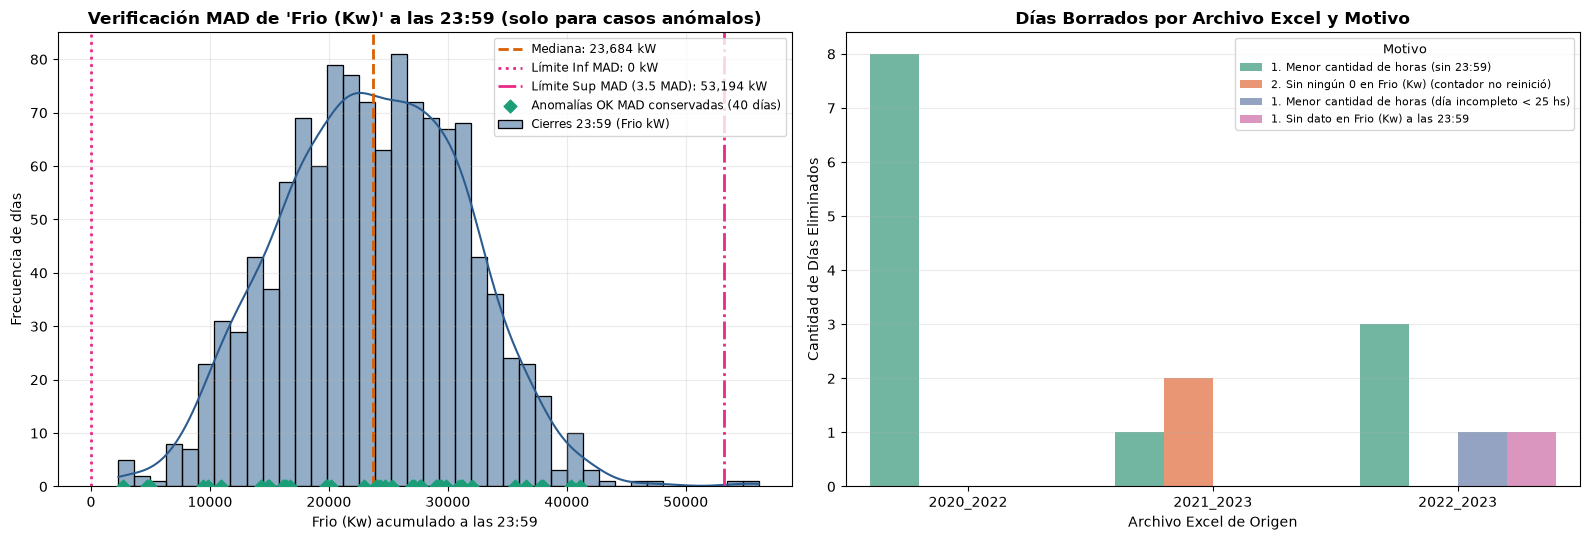

In [57]:
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Distribución del cierre 23:59 de Frio (Kw), umbrales MAD y días anómalos conservados
cierres_frio = df_trabajo[df_trabajo["HORA"] == "23:59"][COL_TARGET].dropna()
cierres_rango_plot = cierres_frio[(cierres_frio >= 0) & (cierres_frio <= 100_000)]

sns.histplot(cierres_rango_plot, bins=40, kde=True, color="#2b5c8f", ax=axes[0], label="Cierres 23:59 (Frio kW)")
axes[0].axvline(ref_mad_frio["Mediana_2359"], color="#d95f02", linestyle="--", linewidth=2, label=f"Mediana: {ref_mad_frio['Mediana_2359']:,.0f} kW")
axes[0].axvline(ref_mad_frio["Lim_Inf_MAD"], color="#e7298a", linestyle=":", linewidth=2, label=f"Límite Inf MAD: {ref_mad_frio['Lim_Inf_MAD']:,.0f} kW")
axes[0].axvline(ref_mad_frio["Lim_Sup_MAD"], color="#e7298a", linestyle="-.", linewidth=2, label=f"Límite Sup MAD ({UMBRAL_MAD} MAD): {ref_mad_frio['Lim_Sup_MAD']:,.0f} kW")
if not df_dias_conservados_mad.empty:
    axes[0].scatter(
        df_dias_conservados_mad["Frio_2359_kW"],
        np.zeros(len(df_dias_conservados_mad)),
        color="#1b9e77",
        marker="D",
        s=42,
        zorder=5,
        label=f"Anomalías OK MAD conservadas ({len(df_dias_conservados_mad)} días)",
    )
axes[0].set_title("Verificación MAD de 'Frio (Kw)' a las 23:59 (solo para casos anómalos)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Frio (Kw) acumulado a las 23:59")
axes[0].set_ylabel("Frecuencia de días")
axes[0].legend(loc="upper right", fontsize=8.5)
axes[0].grid(alpha=0.25)

# Panel 2: Cantidad de días borrados por archivo de origen y categoría
if not df_dias_borrados.empty:
    conteo_plot = (
        df_dias_borrados.groupby(["Archivo_Origen", "Etapa_Filtro"], as_index=False)
        .agg(Dias=("DIA", "count"))
    )
    sns.barplot(
        data=conteo_plot,
        x="Archivo_Origen",
        y="Dias",
        hue="Etapa_Filtro",
        palette="Set2",
        ax=axes[1],
    )
    axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    axes[1].set_title("Días Borrados por Archivo Excel y Motivo", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Archivo Excel de Origen")
    axes[1].set_ylabel("Cantidad de Días Eliminados")
    axes[1].legend(title="Motivo", fontsize=8, title_fontsize=9, loc="upper right")
    axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

--- 
## Etapa 7: Construcción Final y Guardado de `dataset_trabajo.csv` en `data/processed/`

Finalmente:
1. Filtramos el dataset unificado conservando únicamente los días válidos (`dias_validos_finales`).
2. Eliminamos la columna auxiliar interna `_archivo_origen`.
3. Verificamos explícitamente que en el dataset final exista **una única columna `DIA` y una única columna `HORA`** al inicio de la tabla, seguidas por las variables de todas las hojas de los archivos Excel.
4. Guardamos el archivo en `data/processed/dataset_trabajo.csv` (y la tabla de auditoría en `data/processed/tabla_dias_borrados.csv`) y actualizamos `data/checksums.json`.

In [58]:
# ==============================================================================
# ETAPA 7: Exportación de dataset_trabajo.csv, Resumen Final, Checksum y Días Borrados
# ==============================================================================

PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
ruta_salida_csv = PROCESSED_DIR / "dataset_trabajo.csv"

# 1. Preparar el dataframe final (quitando columnas auxiliares internas si existieran)
df_export = df_dataset_final.copy()
cols_aux = [c for c in ["_archivo_origen"] if c in df_export.columns]
df_export_csv = df_export.drop(columns=cols_aux)

# Formatear DIA como YYYY-MM-DD para una exportación limpia y reproducible
df_export_csv["DIA"] = pd.to_datetime(df_export_csv["DIA"]).dt.strftime("%Y-%m-%d")

# 2. Exportar a CSV
df_export_csv.to_csv(ruta_salida_csv, index=False, encoding="utf-8")

# 3. Calcular SHA-256 y actualizar checksums.json
def calcular_sha256_archivo(ruta: Path) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(65536), b""):
            h.update(bloque)
    return h.hexdigest()

try:
    checksum_csv = huella(ruta_salida_csv)
except Exception:
    checksum_csv = calcular_sha256_archivo(ruta_salida_csv)

# Actualizar checksums.json si existe en data/ o en la raíz del proyecto
for ruta_chk in [DATA_DIR / "checksums.json", PROJECT_ROOT / "checksums.json"]:
    if ruta_chk.exists():
        try:
            with open(ruta_chk, "r", encoding="utf-8") as f:
                datos_chk = json.load(f)
            clave_rel = str(ruta_salida_csv.relative_to(PROJECT_ROOT)).replace("\\", "/")
            datos_chk[clave_rel] = checksum_csv
            with open(ruta_chk, "w", encoding="utf-8") as f:
                json.dump(datos_chk, f, indent=2, ensure_ascii=False)
            print(f"Checksum actualizado en: {ruta_chk}")
        except Exception as e:
            print(f"Aviso al actualizar {ruta_chk}: {e}")

# 4. Resumen del Dataset Final + Checksum
n_filas, n_cols = df_export_csv.shape
n_dias_validos = df_export_csv["DIA"].nunique()
fecha_min = df_export_csv["DIA"].min()
fecha_max = df_export_csv["DIA"].max()
tamano_mb = ruta_salida_csv.stat().st_size / (1024 * 1024)

print("=" * 95)
print("RESUMEN FINAL DE 'dataset_trabajo.csv' Y CHECKSUM SHA-256")
print("=" * 95)
print(f"Ruta del archivo exportado : {ruta_salida_csv}")
print(f"Tamaño en disco            : {tamano_mb:.2f} MB")
print(f"Dimensiones finales        : {n_filas:,} filas x {n_cols} columnas")
print(f"Total de días válidos      : {n_dias_validos:,} días (rango: {fecha_min} a {fecha_max})")
print(f"Total de días borrados     : {len(df_dias_borrados)} días")
print(f"SHA-256 Checksum           : {checksum_csv}")
print("=" * 95)

# Distribución de días conservados por archivo de origen
if "_archivo_origen" in df_export.columns:
    print("\n--- Distribución del dataset final por archivo Excel de origen ---")
    resumen_origen = (
        df_export.groupby("_archivo_origen", as_index=False)
        .agg(
            Dias_Conservados=("DIA", "nunique"),
            Filas_Horarias=("HORA", "count"),
            Fecha_Inicio=("DIA", lambda s: pd.to_datetime(s).min().strftime("%Y-%m-%d")),
            Fecha_Fin=("DIA", lambda s: pd.to_datetime(s).max().strftime("%Y-%m-%d")),
        )
    )
    display(resumen_origen)

# 5. Reporte completo de los Días Borrados que quedaron en la tabla
print("\n" + "=" * 95)
print(f"REPORTE DE DÍAS BORRADOS QUE QUEDARON EN LA TABLA ({len(df_dias_borrados)} DÍAS EN TOTAL)")
print("=" * 95)

if not df_dias_borrados.empty:
    col_etapa = "Etapa_Filtro" if "Etapa_Filtro" in df_dias_borrados.columns else "Categoria_Filtro"

    print("\n--- A. Resumen de días borrados por Archivo y Motivo de Filtro ---")
    resumen_borrados = (
        df_dias_borrados.groupby(["Archivo_Origen", col_etapa], as_index=False)
        .agg(
            Cantidad_Dias_Borrados=("DIA", "nunique"),
            Filas_Horarias_Descartadas=("Filas_Dia", "sum"),
        )
        .sort_values(["Archivo_Origen", col_etapa])
        .reset_index(drop=True)
    )
    display(resumen_borrados)

    print("\n--- B. Tabla detallada de todos los días borrados ---")
    cols_mostrar = [
        c for c in [
            "DIA",
            "Archivo_Origen",
            col_etapa,
            "Filas_Dia",
            "Frio_2359_kW",
            "Z_Score_MAD_2359",
            "Motivo_Detallado",
        ]
        if c in df_dias_borrados.columns
    ]
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None, "display.width", None):
        display(df_dias_borrados[cols_mostrar].sort_values("DIA").reset_index(drop=True))
else:
    print("No se registraron días borrados en df_dias_borrados.")

Checksum actualizado en: D:\existencia\facu cosa\tp_final_datos_2\data\checksums.json
RESUMEN FINAL DE 'dataset_trabajo.csv' Y CHECKSUM SHA-256
Ruta del archivo exportado : D:\existencia\facu cosa\tp_final_datos_2\data\processed\dataset_trabajo.csv
Tamaño en disco            : 84.26 MB
Dimensiones finales        : 29,546 filas x 421 columnas
Total de días válidos      : 1,182 días (rango: 2020-07-01 a 2023-10-25)
Total de días borrados     : 16 días
SHA-256 Checksum           : 83999d0963543a28ec7d06138efe525fcd0bac0d44ddee00971c5edae1377907

--- Distribución del dataset final por archivo Excel de origen ---


,_archivo_origen,Dias_Conservados,Filas_Horarias,Fecha_Inicio,Fecha_Fin
0,2020_2022,358,8950,2020-07-01,2021-06-30
1,2021_2023,355,8871,2021-07-02,2022-06-30
2,2022_2023,469,11725,2022-07-01,2023-10-25



REPORTE DE DÍAS BORRADOS QUE QUEDARON EN LA TABLA (16 DÍAS EN TOTAL)

--- A. Resumen de días borrados por Archivo y Motivo de Filtro ---


,Archivo_Origen,Etapa_Filtro,Cantidad_Dias_Borrados,Filas_Horarias_Descartadas
0,2020_2022,1. Menor cantidad de horas (sin 23:59),8,123
1,2021_2023,1. Menor cantidad de horas (sin 23:59),1,23
2,2021_2023,2. Sin ningún 0 en Frio (Kw) (contador no rein...,2,48
3,2022_2023,1. Menor cantidad de horas (día incompleto < 2...,1,16
4,2022_2023,1. Menor cantidad de horas (sin 23:59),3,45
5,2022_2023,1. Sin dato en Frio (Kw) a las 23:59,1,25



--- B. Tabla detallada de todos los días borrados ---


,DIA,Archivo_Origen,Etapa_Filtro,Filas_Dia,Frio_2359_kW,Z_Score_MAD_2359,Motivo_Detallado
0,2020-08-29,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
1,2020-10-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
2,2020-12-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
3,2021-03-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
4,2021-05-31,2020_2022,1. Menor cantidad de horas (sin 23:59),24,NaN,NaN,Día incompleto (24 hs): carece del registro de cierre a las 23:59
5,2021-07-01,2021_2023,2. Sin ningún 0 en Frio (Kw) (contador no reinició),23,"16,411.00",0.86,"Ningún registro del día vale 0 en Frio (Kw) (mínimo=787.0 kW, inicio=02:00)"
6,2021-07-13,2021_2023,1. Menor cantidad de horas (sin 23:59),23,NaN,NaN,Día incompleto (23 hs): carece del registro de cierre a las 23:59
7,2021-08-29,2020_2022,1. Menor cantidad de horas (sin 23:59),1,NaN,NaN,Día incompleto (1 hs): carece del registro de cierre a las 23:59
8,2021-10-31,2020_2022,1. Menor cantidad de horas (sin 23:59),1,NaN,NaN,Día incompleto (1 hs): carece del registro de cierre a las 23:59
9,2021-12-31,2020_2022,1. Menor cantidad de horas (sin 23:59),1,NaN,NaN,Día incompleto (1 hs): carece del registro de cierre a las 23:59


### Q&A
- **¿Los bloques repetidos en días de 50, 75 o 100 registros en `Consolidado EE` son copias o días distintos?**
  La auditoría de la Etapa 1 verifica bloque por bloque contra el `Bloque 0` en `Consolidado EE`, confirmando si corresponden a copias idénticas del propio día o bloques en cero/`NaN`/desbordados generados por plantillas mensuales de 31 días en meses más cortos (conservando únicamente el `Bloque 0`).
- **¿Cómo se tratan los días que no arrancan a las `00:00`, los días con un dato gigante a la `01:00` y las violaciones acumulativas en `Consolidado EE`?**
  El método **MAD** sobre el cierre de las `23:59` en `Frio (Kw)_Consolidado EE` ($Z_{\text{MAD}} \le 3.5$) se evalúa **únicamente cuando ocurre alguna de estas anomalías** (violación acumulativa, falta de reinicio a las `00:00`, valores negativos, inicio $\ne$ `00:00` o dato gigante a la `01:00`), nunca para descartar días normales sanos. Si el cierre a las `23:59` resulta válido según MAD (`OK MAD`), el día **se conserva** (reparando además el pico aislado de la `01:00`).

### Data Analysis Key Findings
- **Desempate temporal por archivo más nuevo:** Ante días registrados en dos archivos Excel distintos, se prioriza el día completo del archivo más reciente (`2022_2023 > 2021_2023 > 2020_2022`), evitando mezclar horas de distintos archivos en una misma fecha.
- **Reparación de errores de tipeo y formato horario:** Se limpia el prefijo `1900-01-01` en `2021-07-21`, se eliminan los registros extra `23:59:59`, se truncan los segundos `:01` y se corrigen los *typos* de secuencia horaria (`16:00 -> 15:00 -> 16:00`, `15:00 -> 15:00`, `09:00 -> 08:00` y `23:00 -> 11:00`).
- **Control acumulativo y método MAD selectivo:** Se auditan todas las variables acumulativas de `Consolidado EE`, reportando cada caída intra-diaria junto con la evaluación MAD de su registro `23:59`; en `Frio (Kw)_Consolidado EE`, los días con violaciones acumulativas o problemas de inicio que aprueban MAD se **conservan**, limitando las bajas únicamente a días incompletos (sin `23:59`, `< 24` hs o `Frio (Kw)` nulo a las `23:59`) o anomalías que efectivamente fallen MAD.

### Insights or Next Steps
- Utilizar `data/processed/dataset_trabajo.csv` como única fuente limpia para el modelado o análisis posterior, teniendo en cuenta que al construir variables *lag* o *targets* diarios ($D+1$) conviene reindexar sobre una grilla calendario diaria continua (`pd.date_range(..., freq='D')`) para no solapar los días que fueron eliminados.
- Consultar `data/processed/tabla_dias_borrados.csv` para auditar individualmente las fechas excluidas de cada archivo Excel.